# 06 &nbsp;Did the email work, and by how much?

**The readout, by the rules set in notebook 02.** Revenue per customer decides. Visits and purchases explain. The secondary metrics get the Holm correction the plan called for. And every number is placed on the decision zones that were drawn *before* any result was looked at.

Two earlier checks make this readout trustworthy:

- **The test is clean** (notebook 01): group sizes match the plan and the groups looked alike before the email.
- **The methods behave at this size** (notebook 03): with over 21,000 customers per group, both the t-test and the bootstrap gave the promised 5% false alarm rate on real revenue data.

In [1]:
import pandas as pd

from exptoolkit import plots, style
from exptoolkit.data import load_hillstrom
from exptoolkit.readout import covariate_matrix, effects_table, variance_reduction
from exptoolkit.spec import load_spec

style.use_style()
spec = load_spec("hillstrom_email.yaml")
df = load_hillstrom()
covariates = ["history", "recency", "mens", "womens", "newbie", "channel", "zip_code"]
table = effects_table(df, spec, covariates=covariates)

## 1. Revenue, three ways

The primary metric is estimated with three methods. If they disagreed, that would be a warning sign. They don't.

In [2]:
labels = {"spend": "Revenue per customer", "visit": "Visited the site", "conversion": "Bought something"}

def p_text(p):
    return "< 0.001" if p < 0.001 else f"{p:.3f}"


def show(rows, money_metric=True):
    out = rows.copy()
    out["Email"] = out["arm"].map(style.ARM_LABELS)
    out["Metric"] = out["metric"].map(labels)
    sign = lambda v: "+" if v >= 0 else "-"
    fmt = ((lambda v: f"{sign(v)}${abs(v):.3f}") if money_metric
           else (lambda v: f"{sign(v)}{100 * abs(v):.2f} pts"))
    out["Lift"] = out["effect"].map(fmt)
    out["95% interval"] = [f"{fmt(lo)} to {fmt(hi)}" for lo, hi in zip(out["ci_low"], out["ci_high"])]
    return out

primary = show(table[table["role"] == "primary"])
primary[["Email", "method", "Lift", "95% interval", "p_value"]].rename(
    columns={"method": "Method", "p_value": "p-value"}
).style.format({"p-value": p_text}).hide(axis="index")

Email,Method,Lift,95% interval,p-value
Men's email,Welch t-test,+$0.770,+$0.485 to +$1.055,< 0.001
Men's email,Bootstrap,+$0.770,+$0.502 to +$1.045,< 0.001
Men's email,CUPED,+$0.767,+$0.482 to +$1.051,< 0.001
Women's email,Welch t-test,+$0.424,+$0.169 to +$0.680,0.001
Women's email,Bootstrap,+$0.424,+$0.179 to +$0.666,0.001
Women's email,CUPED,+$0.425,+$0.169 to +$0.680,0.001


## 2. On the decision map

The decision zones come straight from the plan: 35% margin, $0.02 per email, and at least $20 profit per 1,000 emails to be worth acting on. That means a lift of at least 11.4 cents per customer.

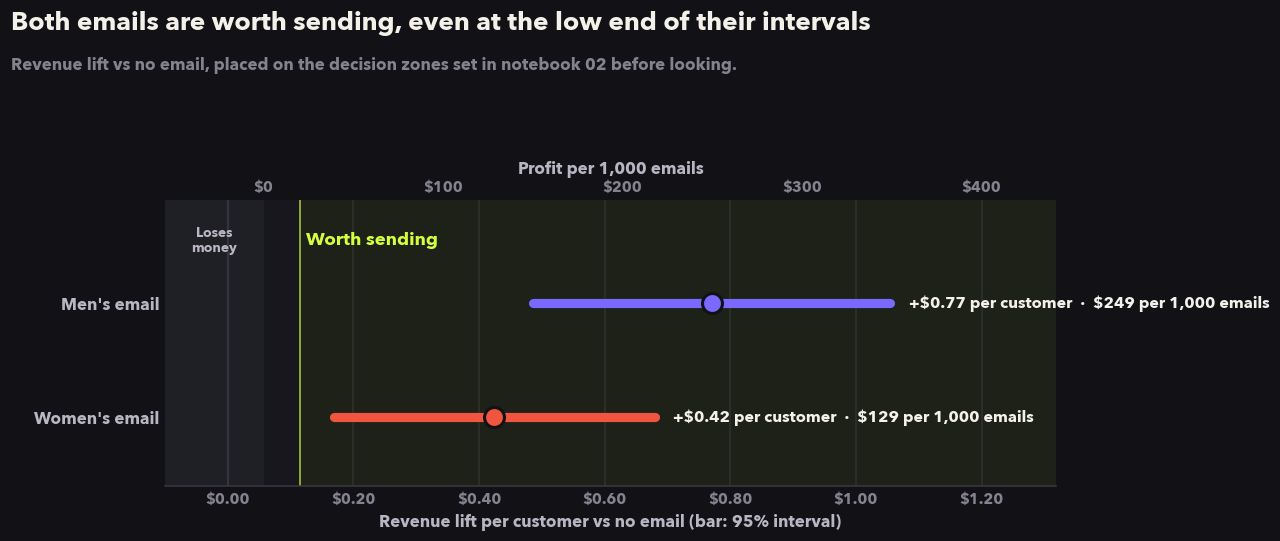

In [3]:
welch = table[(table["role"] == "primary") & (table["method"] == "Welch t-test")].set_index("arm")
results = {arm: (welch.loc[arm, "effect"], welch.loc[arm, "ci_low"], welch.loc[arm, "ci_high"])
           for arm in ["womens_email", "mens_email"]}
fig, ax = plots.decision_map_plot(spec.economics, results)
style.headline(fig, "Both emails are worth sending, even at the low end of their intervals",
               "Revenue lift vs no email, placed on the decision zones set in notebook 02 before looking.")
style.save(fig, "decision_map")

## 3. Did variance reduction help?

**CUPED** subtracts the part of each customer's outcome that was predictable *before* the test, using what we already knew about them. When the prediction is good, the noise drops and the test behaves like a much bigger one. Notebook 04 pointed to it as a way to get more out of the same customers.

How much it helps depends entirely on how well pre-test data predicts the outcome. The share of variance it removes is exactly the share the covariates explain:

In [4]:
X_all = covariate_matrix(df, covariates)
reduction = pd.DataFrame({
    "Past-year spend only": [variance_reduction(df[m], df["history"]) for m in labels],
    "Everything we know before the test": [variance_reduction(df[m], X_all) for m in labels],
}, index=list(labels.values()))
reduction.style.format("{:.2%}")

,Past-year spend only,Everything we know before the test
Revenue per customer,0.05%,0.09%
Visited the site,0.42%,2.67%
Bought something,0.09%,0.19%


**On this data, CUPED does almost nothing.** A year of purchase history explains **less than 0.1%** of what a customer spends in a two-week window, so revenue intervals barely move (compare the CUPED and t-test rows above). Visits do a little better at about 3%.

That is a real finding, not a failure of the method. Whether someone buys in a particular fortnight is close to random, and a yearly total says little about it. CUPED earns its reputation when the covariate is **the same metric measured just before the test**, such as spend in the two weeks before the send. This dataset doesn't have that. In a live test it would be worth logging, and notebook 04's suggestion only holds once it is.

## 4. Secondary metrics, with the Holm correction

Two emails times two secondary metrics is four comparisons. Holm adjusts their p-values so the chance of any false alarm across all four stays at 5%.

In [5]:
secondary = show(table[table["role"] == "secondary"], money_metric=False)
secondary[["Email", "Metric", "Lift", "95% interval", "p_value", "p_adjusted"]].rename(
    columns={"p_value": "p-value", "p_adjusted": "Holm-adjusted"}
).style.format({"p-value": p_text, "Holm-adjusted": p_text}).hide(axis="index")

Email,Metric,Lift,95% interval,p-value,Holm-adjusted
Men's email,Visited the site,+7.66 pts,+7.00 pts to +8.32 pts,< 0.001,< 0.001
Men's email,Bought something,+0.68 pts,+0.50 pts to +0.86 pts,< 0.001,< 0.001
Women's email,Visited the site,+4.52 pts,+3.89 pts to +5.16 pts,< 0.001,< 0.001
Women's email,Bought something,+0.31 pts,+0.15 pts to +0.47 pts,< 0.001,< 0.001


All four survive the correction comfortably. Both emails brought more people to the site and turned more of them into buyers, which is the mechanism behind the revenue lift.

## What this tells us

- **Both emails worked, and both are worth sending.** The men's email lifted revenue by about **77 cents** per customer (95% interval 49 cents to $1.05), worth about **$249 profit per 1,000 emails**. The women's email lifted it by about **42 cents** (17 to 68 cents), about **$129 per 1,000**. Even the low end of each interval clears the 11.4 cent bar set in the plan.
- **Three methods agree.** The t-test, bootstrap and CUPED give the same answer to within a cent or two.
- **The lift comes from more buyers.** Visits and purchases both rose, and both survive the multiple-comparison correction.
- **Not yet answered: which email to send.** The men's email looks better, but its interval overlaps the women's. The plan's rule is about the chance each option is best and the cost of being wrong, which is notebook 07.
- **Still unmeasured: unsubscribes.** The plan named them as a guardrail this dataset can't check, so any recommendation carries that caveat.